# Обучаемые функции

1. Стандартное матричное преобразование с функциями активации (identity, ReLU, tanh)
2. RBF-модификация матричного преобразования
3. Остаточные связи
4. Стабильная функция ошибки SoftmaxCrossEntropy
5. Адаптивный градиентный спуск

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

## 1. Данные

**Wine**:
- Проверка и заполнение пропусков
- Нормализация (StandardScaler)
- Разбиение на тренировочную и тестовую части
- One-hot кодирование меток

In [20]:
data = load_wine()
X, y = data.data, data.target
n_classes = len(np.unique(y))
in_dim = X.shape[1]

print(f"Размер датасета: {X.shape}")
print(f"Классы: {np.unique(y)} (всего {n_classes})")
print(f"Распределение классов: {dict(zip(*np.unique(y, return_counts=True)))}")

n_missing = np.isnan(X).sum()
if n_missing > 0:
    from numpy import nanmedian
    col_medians = nanmedian(X, axis=0)
    for j in range(X.shape[1]):
        mask = np.isnan(X[:, j])
        X[mask, j] = col_medians[j]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

def one_hot(y, n_classes):
    oh = np.zeros((len(y), n_classes))
    oh[np.arange(len(y)), y] = 1
    return oh

y_train_oh = one_hot(y_train, n_classes)
y_test_oh = one_hot(y_test, n_classes)

print(f"\Train: {X_train.shape}")
print(f"Test: {X_test.shape}")

Размер датасета: (178, 13)
Классы: [0 1 2] (всего 3)
Распределение классов: {np.int64(0): np.int64(59), np.int64(1): np.int64(71), np.int64(2): np.int64(48)}
\Train: (142, 13)
Test: (36, 13)


## 2. Функции активации и стандартное обучаемое преобразование

- **Identity**: $$f(x) = x, f'(x) = 1$$
- **ReLU**: $$f(x) = \max(0, x), f'(x) = \mathbb{1}[x > 0]$$
- **tanh**: $$f(x) = \tanh(x), f'(x) = 1 - \tanh^2(x)$$

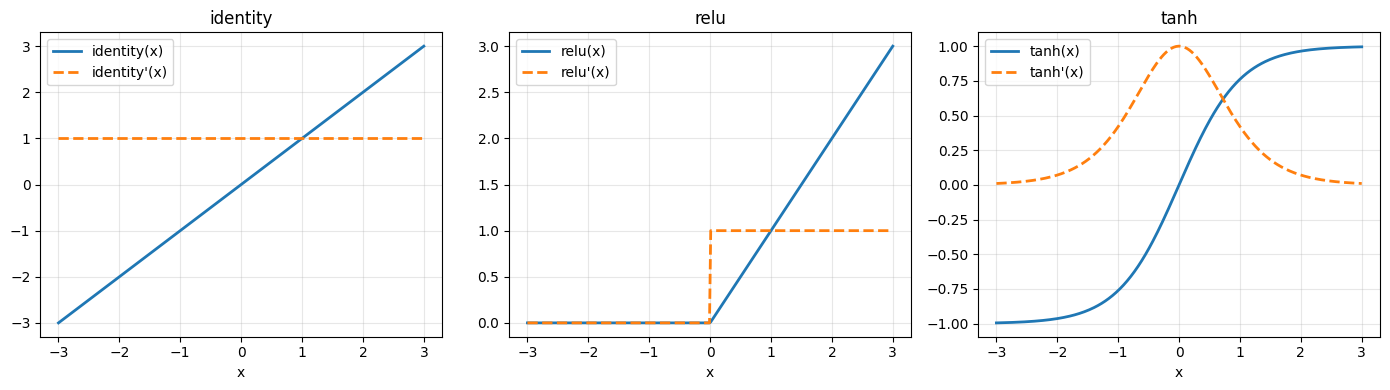

In [21]:
class Activation:
    @staticmethod
    def forward(Z, name):
        if name == 'identity':
            return Z.copy()
        elif name == 'relu':
            return np.maximum(0, Z)
        elif name == 'tanh':
            return np.tanh(Z)
        else:
            raise ValueError(f"Bebebe: {name}")

    @staticmethod
    def derivative(Z, name):
        if name == 'identity':
            return np.ones_like(Z)
        elif name == 'relu':
            return (Z > 0).astype(float)
        elif name == 'tanh':
            t = np.tanh(Z)
            return 1.0 - t ** 2
        else:
            raise ValueError(f"Bebeb: {name}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
x = np.linspace(-3, 3, 300)
for ax, name in zip(axes, ['identity', 'relu', 'tanh']):
    y = Activation.forward(x, name)
    dy = Activation.derivative(x, name)
    ax.plot(x, y, label=f'{name}(x)', linewidth=2)
    ax.plot(x, dy, '--', label=f"{name}'(x)", linewidth=2)
    ax.set_title(name)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.set_xlabel('x')
plt.tight_layout()
plt.show()

$$\mathbf{a} = \sigma(W \cdot \mathbf{x} + \mathbf{b})$$

Где $W \in \mathbb{R}^{d_{\text{out}} \times d_{\text{in}}}$, $\mathbf{b} \in \mathbb{R}^{d_{\text{out}}}$, $\sigma$ — функция активации.

Обратное распространение:
- $$\frac{\partial L}{\partial Z} = \frac{\partial L}{\partial A} \odot \sigma'(Z)$$
- $$\frac{\partial L}{\partial W} = \frac{\partial L}{\partial Z} \cdot X^T $$
- $$\frac{\partial L}{\partial b} = \sum_{\text{batch}} \frac{\partial L}{\partial Z}$$
- $$\frac{\partial L}{\partial X} = W^T \cdot \frac{\partial L}{\partial Z}$$

In [22]:
class LinearLayer:
    def __init__(self, in_dim, out_dim, activation='relu'):
        scale = np.sqrt(2.0 / (in_dim + out_dim))
        self.W = np.random.randn(in_dim, out_dim) * scale
        self.b = np.zeros((1, out_dim))
        self.activation_name = activation

        self._X = None
        self._Z = None

        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, X):
        self._X = X
        self._Z = X @ self.W + self.b
        return Activation.forward(self._Z, self.activation_name)

    def backward(self, grad_output):
        dZ = grad_output * Activation.derivative(self._Z, self.activation_name)
        self.dW = self._X.T @ dZ
        self.db = np.sum(dZ, axis=0, keepdims=True)
        dX = dZ @ self.W.T
        return dX

    def get_params(self):
        return [self.W, self.b]

    def get_grads(self):
        return [self.dW, self.db]

    def n_params(self):
        return self.W.size + self.b.size

## 3. RBF преобразование

Модификация линейного преобразования: скалярное произведение заменяем на RBF:

$$K_j(\mathbf{x}) = \exp\left(-\gamma \|\mathbf{x} - \mathbf{w}_j\|^2\right)$$

$$z_j = K_j(\mathbf{x}) + b_j, \quad a_j = \sigma(z_j)$$

Обратное распространение:
- $$\frac{\partial K_j}{\partial x_i} = K_j \cdot (-2\gamma)(x_i - w_{ji})$$
- $$\frac{\partial K_j}{\partial w_{ji}} = K_j \cdot 2\gamma (x_i - w_{ji})$$

In [23]:
class RBFLayer:

    def __init__(self, in_dim, out_dim, gamma=None, activation='relu'):
        self.gamma = gamma if gamma is not None else 1.0 / in_dim
        scale = np.sqrt(2.0 / (in_dim + out_dim))
        self.W = np.random.randn(out_dim, in_dim) * scale
        self.b = np.zeros((1, out_dim))
        self.activation_name = activation

        self._X = None
        self._Z = None
        self._K = None
        self._diff = None

        self.dW = np.zeros_like(self.W)
        self.db = np.zeros_like(self.b)

    def forward(self, X):
        self._X = X
        self._diff = X[:, np.newaxis, :] - self.W[np.newaxis, :, :]
        dist_sq = np.sum(self._diff ** 2, axis=2)
        self._K = np.exp(-self.gamma * dist_sq)
        self._Z = self._K + self.b
        return Activation.forward(self._Z, self.activation_name)

    def backward(self, grad_output):
        dZ = grad_output * Activation.derivative(self._Z, self.activation_name)
        self.db = np.sum(dZ, axis=0, keepdims=True)

        dK = dZ
        d_dist = dK * self._K * (-self.gamma)
        d_diff = d_dist[:, :, np.newaxis] * 2.0 * self._diff
        dX = np.sum(d_diff, axis=1)
        self.dW = -np.sum(d_diff, axis=0)

        return dX

    def get_params(self):
        return [self.W, self.b]

    def get_grads(self):
        return [self.dW, self.db]

    def n_params(self):
        return self.W.size + self.b.size

## 4. Остаточная связь

Обёртка добавляет остаточную связь к преобразованию: $\mathbf{y} = f(\mathbf{x}) + \mathbf{x}$. Что не даёт градиенту затухать при обратном ходе сети.

 Градиент: $\frac{\partial L}{\partial \mathbf{x}} = \frac{\partial L}{\partial \mathbf{y}} \cdot \left(\frac{\partial f}{\partial \mathbf{x}} + I\right)$

In [24]:
class ResidualWrapper:
    def __init__(self, layer):
        self.layer = layer

    def forward(self, X):
        self._X = X
        return self.layer.forward(X) + X

    def backward(self, grad_output):
        return self.layer.backward(grad_output) + grad_output

    def get_params(self):
        return self.layer.get_params()

    def get_grads(self):
        return self.layer.get_grads()

    def n_params(self):
        return self.layer.n_params()

## 5. SoftArgMaxCrossEntropy

$$\text{softmax}(\mathbf{z})_i = \frac{\exp(z_i - \max(\mathbf{z}))}{\sum_j \exp(z_j - \max(\mathbf{z}))}$$

$$L = -\frac{1}{N}\sum_{n=1}^{N}\sum_{c=1}^{C} y_{nc} \log(\text{softmax}(\mathbf{z}_n)_c)$$

Градиент: $\frac{\partial L}{\partial z_{nc}} = \frac{1}{N}(\text{softmax}(\mathbf{z}_n)_c - y_{nc})$

In [25]:
class SoftmaxCrossEntropy:

    def __init__(self):
        self._probs = None
        self._targets = None

    def forward(self, logits, targets):
        shifted = logits - np.max(logits, axis=1, keepdims=True)
        exp_shifted = np.exp(shifted)
        self._probs = exp_shifted / np.sum(exp_shifted, axis=1, keepdims=True)
        self._targets = targets

        log_sum_exp = np.log(np.sum(exp_shifted, axis=1, keepdims=True))
        log_probs = shifted - log_sum_exp

        loss = -np.sum(targets * log_probs) / len(logits)
        return loss

    def backward(self):
        return (self._probs - self._targets) / len(self._targets)

loss_fn = SoftmaxCrossEntropy()
logits_test = np.array([[2.0, 1.0, 0.1], [0.5, 2.5, 0.3]])
targets_test = np.array([[1, 0, 0], [0, 1, 0]], dtype=float)
loss_val = loss_fn.forward(logits_test, targets_test)
grad_val = loss_fn.backward()
print(f"Тестовый loss: {loss_val:.4f}")
print(f"Тестовый градиент:\n{grad_val}")

Тестовый loss: 0.3185
Тестовый градиент:
[[-0.17049943  0.12121649  0.04928295]
 [ 0.05430187 -0.09876047  0.04445861]]


## 6. Адаптивный градиентный спус

Оптимизатор Adam с адаптивным learning rate:
- $$m_t = \beta_1 m_{t-1} + (1-\beta_1) g_t$$
- $$v_t = \beta_2 v_{t-1} + (1-\beta_2) g_t^2$$
- $$\hat{m}_t = m_t / (1 - \beta_1^t), \hat{v}_t = v_t / (1 - \beta_2^t)$$
- $$\theta_t = \theta_{t-1} - \alpha \hat{m}_t / (\sqrt{\hat{v}_t} + \epsilon)$$

In [26]:
class Adam:
    def __init__(self, lr=0.001, beta1=0.9, beta2=0.999, eps=1e-8):
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0
        self._m = None
        self._v = None

    def step(self, params, grads):
        if self._m is None:
            self._m = [np.zeros_like(p) for p in params]
            self._v = [np.zeros_like(p) for p in params]

        self.t += 1
        for i in range(len(params)):
            self._m[i] = self.beta1 * self._m[i] + (1 - self.beta1) * grads[i]
            self._v[i] = self.beta2 * self._v[i] + (1 - self.beta2) * grads[i] ** 2
            m_hat = self._m[i] / (1 - self.beta1 ** self.t)
            v_hat = self._v[i] / (1 - self.beta2 ** self.t)
            params[i] -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)

## 7. Последовательная модель и обучение

In [27]:
class Sequential:
    def __init__(self, layers):
        self.layers = layers

    def forward(self, X):
        for layer in self.layers:
            X = layer.forward(X)
        return X

    def backward(self, grad):
        for layer in reversed(self.layers):
            grad = layer.backward(grad)
        return grad

    def get_params(self):
        params = []
        for layer in self.layers:
            params.extend(layer.get_params())
        return params

    def get_grads(self):
        grads = []
        for layer in self.layers:
            grads.extend(layer.get_grads())
        return grads

    def n_params(self):
        return sum(layer.n_params() for layer in self.layers)


def train_model(model, X_train, y_train_oh, X_test, y_test_oh,
                epochs=500, batch_size=32, lr=0.001, verbose=True):
    loss_fn = SoftmaxCrossEntropy()
    optimizer = Adam(lr=lr)
    n = len(X_train)

    train_losses = []
    test_losses = []

    for epoch in range(epochs):
        perm = np.random.permutation(n)

        for start in range(0, n, batch_size):
            end = min(start + batch_size, n)
            idx = perm[start:end]
            X_batch = X_train[idx]
            y_batch = y_train_oh[idx]

            logits = model.forward(X_batch)
            loss_fn.forward(logits, y_batch)

            grad = loss_fn.backward()
            model.backward(grad)

            optimizer.step(model.get_params(), model.get_grads())

        train_logits = model.forward(X_train)
        train_loss = loss_fn.forward(train_logits, y_train_oh)
        train_losses.append(train_loss)

        test_logits = model.forward(X_test)
        test_loss = loss_fn.forward(test_logits, y_test_oh)
        test_losses.append(test_loss)

        if verbose and (epoch + 1) % 100 == 0:
            print(f"  Эпоха {epoch+1}/{epochs}: train_loss={train_loss:.4f}, test_loss={test_loss:.4f}")

    return train_losses, test_losses


def evaluate_model(model, X, y_true):
    logits = model.forward(X)
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(y_true, preds)
    f1 = f1_score(y_true, preds, average='macro')
    return acc, f1

In [28]:
def build_standard_model(in_dim, n_classes, n_layers, hidden_dim=32,
                         activation='relu', residual=False):
    layers = []
    if n_layers == 1:
        layers.append(LinearLayer(in_dim, n_classes, 'identity'))
    else:
        layers.append(LinearLayer(in_dim, hidden_dim, activation))
        for _ in range(n_layers - 2):
            layer = LinearLayer(hidden_dim, hidden_dim, activation)
            if residual:
                layer = ResidualWrapper(layer)
            layers.append(layer)
        layers.append(LinearLayer(hidden_dim, n_classes, 'identity'))
    return Sequential(layers)


def build_rbf_model(in_dim, n_classes, n_layers, hidden_dim=32,
                    gamma=None, activation='relu', residual=False):
    layers = []
    if n_layers == 1:
        layers.append(RBFLayer(in_dim, n_classes, gamma=gamma, activation='identity'))
    else:
        layers.append(RBFLayer(in_dim, hidden_dim, gamma=gamma, activation=activation))
        for _ in range(n_layers - 2):
            layer = RBFLayer(hidden_dim, hidden_dim, gamma=gamma, activation=activation)
            if residual:
                layer = ResidualWrapper(layer)
            layers.append(layer)
        layers.append(RBFLayer(hidden_dim, n_classes, gamma=gamma, activation='identity'))
    return Sequential(layers)


def build_combined_model(in_dim, n_classes, config, hidden_dim=32,
                         gamma=None, activation='relu', residual=False):
    layers = []
    dims = [in_dim] + [hidden_dim] * (len(config) - 1) + [n_classes]
    for i, layer_type in enumerate(config):
        is_last = (i == len(config) - 1)
        act = 'identity' if is_last else activation
        d_in, d_out = dims[i], dims[i + 1]
        if layer_type == 'linear':
            layer = LinearLayer(d_in, d_out, act)
        else:
            layer = RBFLayer(d_in, d_out, gamma=gamma, activation=act)
        if residual and not is_last and i > 0 and d_in == d_out:
            layer = ResidualWrapper(layer)
        layers.append(layer)
    return Sequential(layers)


def run_experiments(configs, X_train, y_train_oh, X_test, y_test_oh,
                    y_train, y_test, epochs=500, batch_size=32):
    results = {}
    for name, (builder, kwargs) in configs.items():
        print(f"\n{'='*50}")
        print(f"Модель: {name}")
        np.random.seed(42)
        build_kwargs = {k: v for k, v in kwargs.items() if k != 'lr'}
        model = builder(**build_kwargs)
        n_p = model.n_params()
        print(f"Параметров: {n_p}")

        lr = kwargs.get('lr', 0.005)
        train_losses, test_losses = train_model(
            model, X_train, y_train_oh, X_test, y_test_oh,
            epochs=epochs, batch_size=batch_size, lr=lr, verbose=True
        )

        train_acc, train_f1 = evaluate_model(model, X_train, y_train)
        test_acc, test_f1 = evaluate_model(model, X_test, y_test)
        print(f"Train: acc={train_acc:.4f}, F1={train_f1:.4f}")
        print(f"Test:  acc={test_acc:.4f}, F1={test_f1:.4f}")

        results[name] = {
            'train_losses': train_losses,
            'test_losses': test_losses,
            'train_acc': train_acc, 'test_acc': test_acc,
            'train_f1': train_f1, 'test_f1': test_f1,
            'n_params': n_p,
            'n_layers': kwargs.get('n_layers', len(kwargs.get('config', [])))
        }
    return results


def plot_results(results, title_prefix=""):
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    ax = axes[0]
    for name, res in results.items():
        ax.plot(res['train_losses'], label=name, alpha=0.8)
    ax.set_xlabel('Эпоха')
    ax.set_ylabel('Train Loss')
    ax.set_title(f'{title_prefix}Кривые обучения')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)
    ax.set_yscale('log')

    ax = axes[1]
    names = list(results.keys())
    n_params_list = [results[n]['n_params'] for n in names]
    test_accs = [results[n]['test_acc'] for n in names]
    test_f1s = [results[n]['test_f1'] for n in names]
    ax.scatter(n_params_list, test_accs, s=80, zorder=5)
    for i, name in enumerate(names):
        ax.annotate(name, (n_params_list[i], test_accs[i]),
                    fontsize=7, ha='center', va='bottom')
    ax.set_xlabel('Число параметров')
    ax.set_ylabel('Test Accuracy')
    ax.set_title(f'{title_prefix}Accuracy vs параметры')
    ax.grid(True, alpha=0.3)

    ax = axes[2]
    n_layers_list = [results[n]['n_layers'] for n in names]
    ax.bar(range(len(names)), test_f1s, tick_label=names, alpha=0.7)
    ax.set_ylabel('Test F1 (macro)')
    ax.set_title(f'{title_prefix}F1 по моделям')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3, axis='y')

    plt.tight_layout()
    plt.show()

    print(f"\n{'Модель':<30} {'Параметры':>10} {'Train Acc':>10} {'Test Acc':>10} {'Test F1':>10}")
    print('-' * 75)
    for name, res in results.items():
        print(f"{name:<30} {res['n_params']:>10} {res['train_acc']:>10.4f} "
              f"{res['test_acc']:>10.4f} {res['test_f1']:>10.4f}")


## 7.1. Эксперименты со стандартными матричными преобразованиями

Обучаем модели с разным числом стандартных линейных слоёв (1–4). Для моделей с 3+ слоями также проверяем влияние остаточных связей.

In [29]:
HIDDEN = 32
EPOCHS = 500
BATCH = 32
LR_STD = 0.005

standard_configs = {
    '1 слой': (build_standard_model,
               dict(in_dim=in_dim, n_classes=n_classes, n_layers=1, hidden_dim=HIDDEN, lr=LR_STD)),
    '2 слоя': (build_standard_model,
               dict(in_dim=in_dim, n_classes=n_classes, n_layers=2, hidden_dim=HIDDEN, lr=LR_STD)),
    '3 слоя': (build_standard_model,
               dict(in_dim=in_dim, n_classes=n_classes, n_layers=3, hidden_dim=HIDDEN, lr=LR_STD)),
    '4 слоя': (build_standard_model,
               dict(in_dim=in_dim, n_classes=n_classes, n_layers=4, hidden_dim=HIDDEN, lr=0.003)),
    '3 + residual': (build_standard_model,
                     dict(in_dim=in_dim, n_classes=n_classes, n_layers=3, hidden_dim=HIDDEN,
                          residual=True, lr=LR_STD)),
    '4 + residual': (build_standard_model,
                     dict(in_dim=in_dim, n_classes=n_classes, n_layers=4, hidden_dim=HIDDEN,
                          residual=True, lr=0.003)),
}

std_results = run_experiments(standard_configs, X_train, y_train_oh, X_test, y_test_oh,
                              y_train, y_test, epochs=EPOCHS, batch_size=BATCH)


Модель: 1 слой
Параметров: 42
  Эпоха 100/500: train_loss=0.0428, test_loss=0.0718
  Эпоха 200/500: train_loss=0.0193, test_loss=0.0623
  Эпоха 300/500: train_loss=0.0112, test_loss=0.0607
  Эпоха 400/500: train_loss=0.0073, test_loss=0.0621
  Эпоха 500/500: train_loss=0.0050, test_loss=0.0634
Train: acc=1.0000, F1=1.0000
Test:  acc=0.9722, F1=0.9710

Модель: 2 слоя
Параметров: 547
  Эпоха 100/500: train_loss=0.0009, test_loss=0.0721
  Эпоха 200/500: train_loss=0.0003, test_loss=0.0803
  Эпоха 300/500: train_loss=0.0001, test_loss=0.0874
  Эпоха 400/500: train_loss=0.0001, test_loss=0.0929
  Эпоха 500/500: train_loss=0.0000, test_loss=0.0978
Train: acc=1.0000, F1=1.0000
Test:  acc=0.9444, F1=0.9407

Модель: 3 слоя
Параметров: 1603
  Эпоха 100/500: train_loss=0.0001, test_loss=0.1091
  Эпоха 200/500: train_loss=0.0000, test_loss=0.1153
  Эпоха 300/500: train_loss=0.0000, test_loss=0.1200
  Эпоха 400/500: train_loss=0.0000, test_loss=0.1221
  Эпоха 500/500: train_loss=0.0000, test_loss=

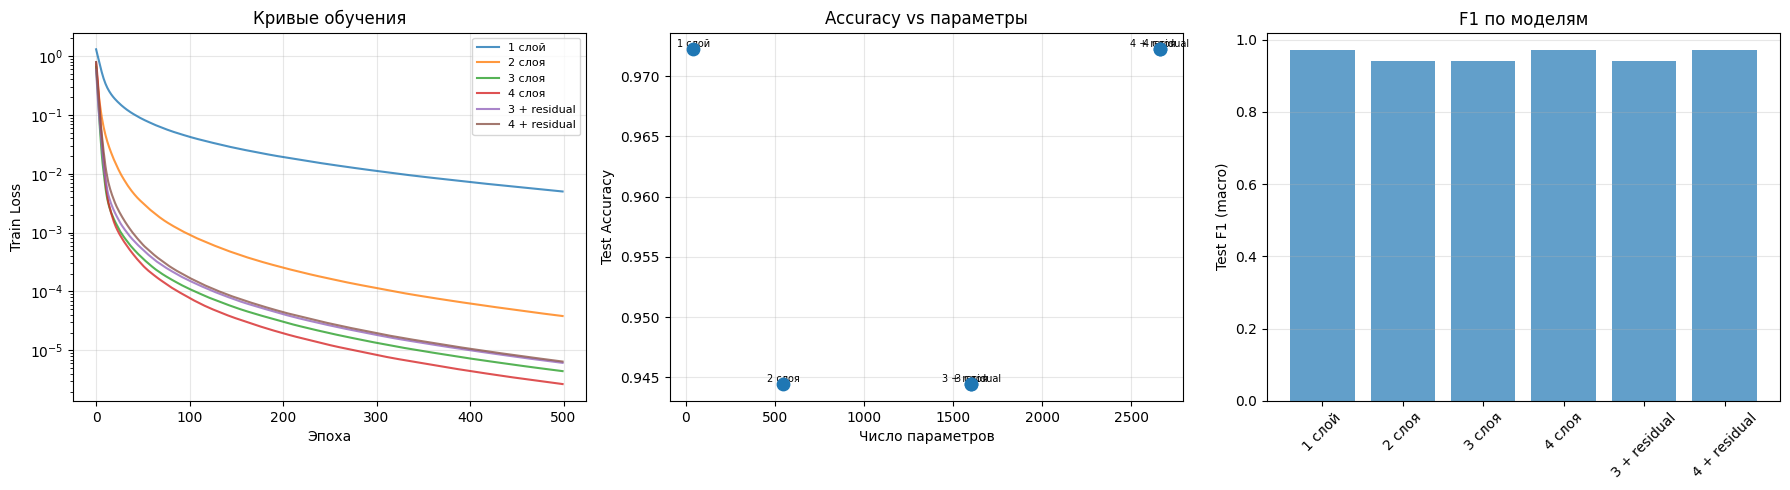


Модель                          Параметры  Train Acc   Test Acc    Test F1
---------------------------------------------------------------------------
1 слой                                 42     1.0000     0.9722     0.9710
2 слоя                                547     1.0000     0.9444     0.9407
3 слоя                               1603     1.0000     0.9444     0.9407
4 слоя                               2659     1.0000     0.9722     0.9710
3 + residual                         1603     1.0000     0.9444     0.9407
4 + residual                         2659     1.0000     0.9722     0.9710


In [30]:
plot_results(std_results, title_prefix="")

## 8. RBF преобразования

Повторяем эксперименты, заменив стандартные линейные слои на RBF. Каждую координату выхода вычислим как $\exp(-\gamma\|\mathbf{x} - \mathbf{w}_j\|^2) + b_j$.

In [31]:
LR_RBF = 0.003
GAMMA = 0.05

rbf_configs = {
    'RBF 1 слой': (build_rbf_model,
                   dict(in_dim=in_dim, n_classes=n_classes, n_layers=1, hidden_dim=HIDDEN,
                        gamma=GAMMA, lr=LR_RBF)),
    'RBF 2 слоя': (build_rbf_model,
                   dict(in_dim=in_dim, n_classes=n_classes, n_layers=2, hidden_dim=HIDDEN,
                        gamma=GAMMA, lr=LR_RBF)),
    'RBF 3 слоя': (build_rbf_model,
                   dict(in_dim=in_dim, n_classes=n_classes, n_layers=3, hidden_dim=HIDDEN,
                        gamma=GAMMA, lr=0.002)),
    'RBF 4 слоя': (build_rbf_model,
                   dict(in_dim=in_dim, n_classes=n_classes, n_layers=4, hidden_dim=HIDDEN,
                        gamma=GAMMA, lr=0.001)),
    'RBF 3 + res': (build_rbf_model,
                    dict(in_dim=in_dim, n_classes=n_classes, n_layers=3, hidden_dim=HIDDEN,
                         gamma=GAMMA, residual=True, lr=0.002)),
    'RBF 4 + res': (build_rbf_model,
                    dict(in_dim=in_dim, n_classes=n_classes, n_layers=4, hidden_dim=HIDDEN,
                         gamma=GAMMA, residual=True, lr=0.001)),
}

rbf_results = run_experiments(rbf_configs, X_train, y_train_oh, X_test, y_test_oh,
                              y_train, y_test, epochs=EPOCHS, batch_size=BATCH)


Модель: RBF 1 слой
Параметров: 42
  Эпоха 100/500: train_loss=0.8187, test_loss=0.8191
  Эпоха 200/500: train_loss=0.8032, test_loss=0.8007
  Эпоха 300/500: train_loss=0.8028, test_loss=0.7997
  Эпоха 400/500: train_loss=0.8028, test_loss=0.7999
  Эпоха 500/500: train_loss=0.8028, test_loss=0.7995
Train: acc=0.9014, F1=0.9000
Test:  acc=0.8889, F1=0.8850

Модель: RBF 2 слоя
Параметров: 547
  Эпоха 100/500: train_loss=0.8652, test_loss=0.8650
  Эпоха 200/500: train_loss=0.8570, test_loss=0.8534
  Эпоха 300/500: train_loss=0.8565, test_loss=0.8533
  Эпоха 400/500: train_loss=0.8564, test_loss=0.8531
  Эпоха 500/500: train_loss=0.8565, test_loss=0.8532
Train: acc=0.7254, F1=0.6157
Test:  acc=0.7778, F1=0.7319

Модель: RBF 3 слоя
Параметров: 1603
  Эпоха 100/500: train_loss=0.9903, test_loss=0.9917
  Эпоха 200/500: train_loss=0.9422, test_loss=0.9380
  Эпоха 300/500: train_loss=0.9337, test_loss=0.9302
  Эпоха 400/500: train_loss=0.9319, test_loss=0.9287
  Эпоха 500/500: train_loss=0.9316

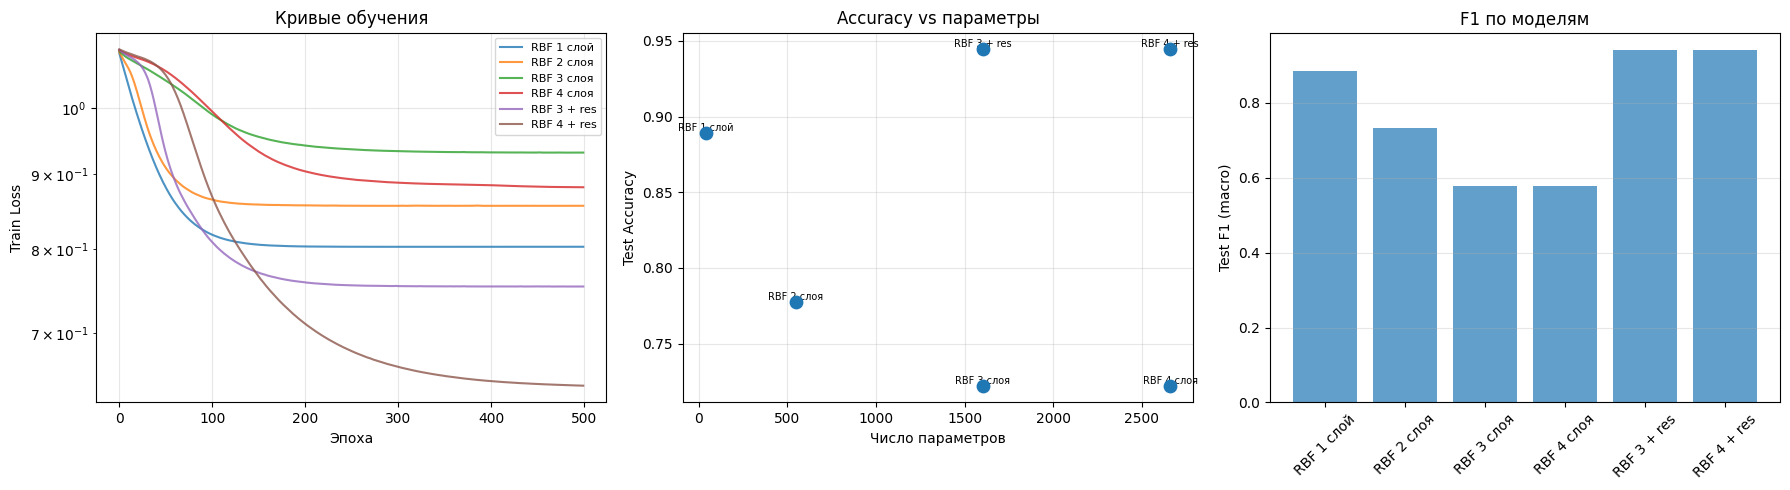


Модель                          Параметры  Train Acc   Test Acc    Test F1
---------------------------------------------------------------------------
RBF 1 слой                             42     0.9014     0.8889     0.8850
RBF 2 слоя                            547     0.7254     0.7778     0.7319
RBF 3 слоя                           1603     0.7254     0.7222     0.5789
RBF 4 слоя                           2659     0.7254     0.7222     0.5789
RBF 3 + res                          1603     0.9577     0.9444     0.9407
RBF 4 + res                          2659     0.9859     0.9444     0.9407


In [32]:
plot_results(rbf_results, title_prefix="")

## 9. Комбинация стандартных и RBF преобразований

Модели, комбинирующие оба типа слоёв.
- Linear → RBF → Linear
- RBF → Linear → RBF
- Linear → RBF → Linear → Linear
- RBF → Linear → RBF → Linear

In [33]:
LR_COMB = 0.003

combined_configs = {
    'Lin-RBF-Lin (3)': (build_combined_model,
                        dict(in_dim=in_dim, n_classes=n_classes,
                             config=['linear', 'rbf', 'linear'],
                             hidden_dim=HIDDEN, gamma=GAMMA, lr=LR_COMB)),
    'RBF-Lin-RBF (3)': (build_combined_model,
                        dict(in_dim=in_dim, n_classes=n_classes,
                             config=['rbf', 'linear', 'rbf'],
                             hidden_dim=HIDDEN, gamma=GAMMA, lr=LR_COMB)),
    'Lin-RBF-Lin-Lin (4)': (build_combined_model,
                            dict(in_dim=in_dim, n_classes=n_classes,
                                 config=['linear', 'rbf', 'linear', 'linear'],
                                 hidden_dim=HIDDEN, gamma=GAMMA, lr=0.002)),
    'RBF-Lin-RBF-Lin (4)': (build_combined_model,
                            dict(in_dim=in_dim, n_classes=n_classes,
                                 config=['rbf', 'linear', 'rbf', 'linear'],
                                 hidden_dim=HIDDEN, gamma=GAMMA, lr=0.002)),
    'Lin-RBF-Lin + res (3)': (build_combined_model,
                              dict(in_dim=in_dim, n_classes=n_classes,
                                   config=['linear', 'rbf', 'linear'],
                                   hidden_dim=HIDDEN, gamma=GAMMA, residual=True, lr=LR_COMB)),
    'RBF-Lin-Lin-Lin + res (4)': (build_combined_model,
                                  dict(in_dim=in_dim, n_classes=n_classes,
                                       config=['rbf', 'linear', 'linear', 'linear'],
                                       hidden_dim=HIDDEN, gamma=GAMMA, residual=True, lr=0.002)),
}

comb_results = run_experiments(combined_configs, X_train, y_train_oh, X_test, y_test_oh,
                               y_train, y_test, epochs=EPOCHS, batch_size=BATCH)


Модель: Lin-RBF-Lin (3)
Параметров: 1603
  Эпоха 100/500: train_loss=0.0136, test_loss=0.0710
  Эпоха 200/500: train_loss=0.0033, test_loss=0.0689
  Эпоха 300/500: train_loss=0.0015, test_loss=0.0757
  Эпоха 400/500: train_loss=0.0008, test_loss=0.0870
  Эпоха 500/500: train_loss=0.0005, test_loss=0.0948
Train: acc=1.0000, F1=1.0000
Test:  acc=0.9167, F1=0.9151

Модель: RBF-Lin-RBF (3)
Параметров: 1603
  Эпоха 100/500: train_loss=0.6547, test_loss=0.6749
  Эпоха 200/500: train_loss=0.6017, test_loss=0.6271
  Эпоха 300/500: train_loss=0.5911, test_loss=0.6192
  Эпоха 400/500: train_loss=0.5845, test_loss=0.6148
  Эпоха 500/500: train_loss=0.5795, test_loss=0.6117
Train: acc=1.0000, F1=1.0000
Test:  acc=0.9444, F1=0.9407

Модель: Lin-RBF-Lin-Lin (4)
Параметров: 2659
  Эпоха 100/500: train_loss=0.0016, test_loss=0.0529
  Эпоха 200/500: train_loss=0.0003, test_loss=0.0507
  Эпоха 300/500: train_loss=0.0001, test_loss=0.0516
  Эпоха 400/500: train_loss=0.0001, test_loss=0.0522
  Эпоха 500/

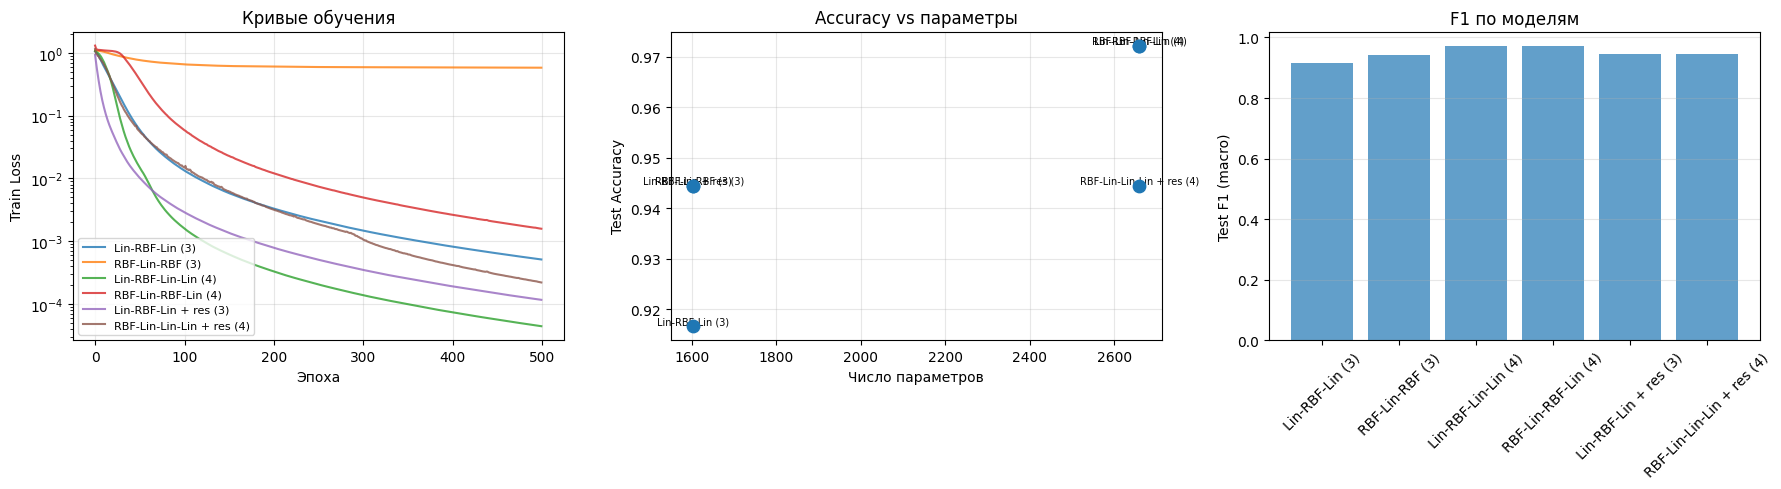


Модель                          Параметры  Train Acc   Test Acc    Test F1
---------------------------------------------------------------------------
Lin-RBF-Lin (3)                      1603     1.0000     0.9167     0.9151
RBF-Lin-RBF (3)                      1603     1.0000     0.9444     0.9407
Lin-RBF-Lin-Lin (4)                  2659     1.0000     0.9722     0.9710
RBF-Lin-RBF-Lin (4)                  2659     1.0000     0.9722     0.9710
Lin-RBF-Lin + res (3)                1603     1.0000     0.9444     0.9453
RBF-Lin-Lin-Lin + res (4)            2659     1.0000     0.9444     0.9457


In [34]:
plot_results(comb_results, title_prefix="")

## Все модели

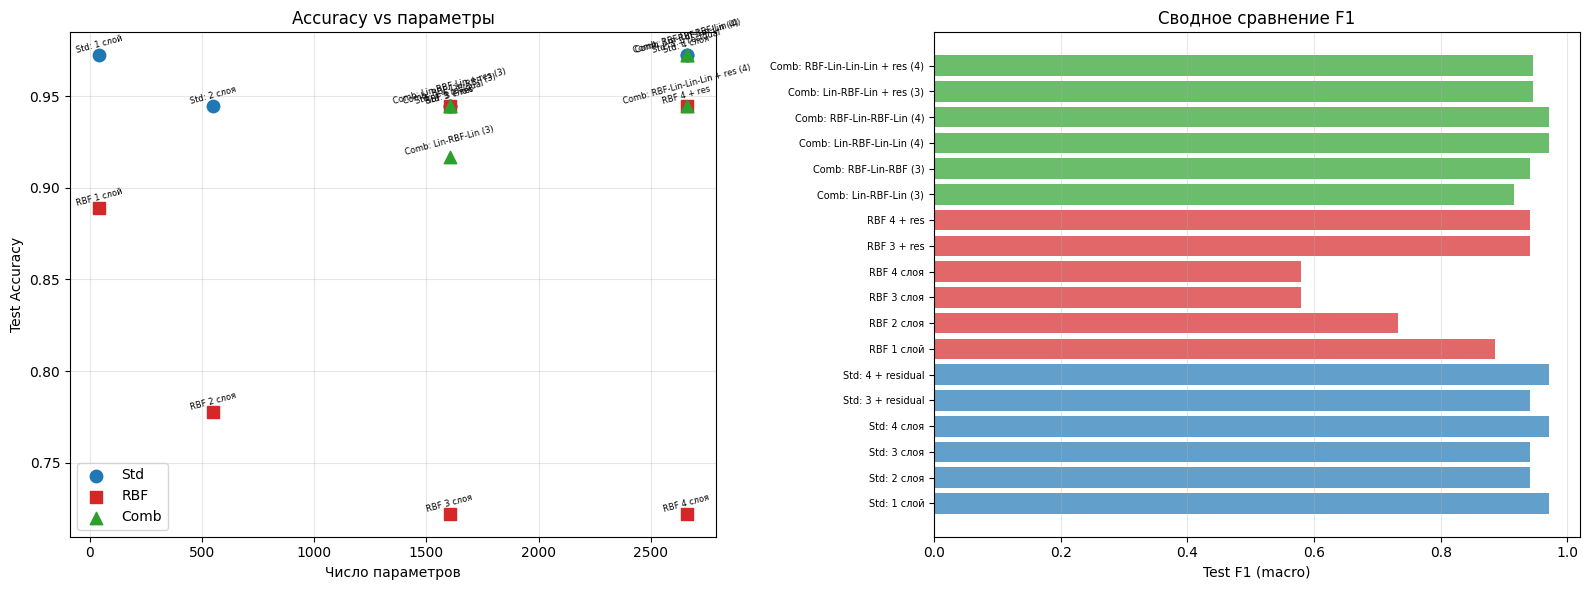


Модель                              Тип        Парам.  Train Acc   Test Acc    Test F1
Std: 1 слой                         Std            42     1.0000     0.9722     0.9710
Std: 2 слоя                         Std           547     1.0000     0.9444     0.9407
Std: 3 слоя                         Std          1603     1.0000     0.9444     0.9407
Std: 4 слоя                         Std          2659     1.0000     0.9722     0.9710
Std: 3 + residual                   Std          1603     1.0000     0.9444     0.9407
Std: 4 + residual                   Std          2659     1.0000     0.9722     0.9710
RBF 1 слой                          RBF            42     0.9014     0.8889     0.8850
RBF 2 слоя                          RBF           547     0.7254     0.7778     0.7319
RBF 3 слоя                          RBF          1603     0.7254     0.7222     0.5789
RBF 4 слоя                          RBF          2659     0.7254     0.7222     0.5789
RBF 3 + res                         RBF   

In [35]:
all_results = {}
for name, res in std_results.items():
    all_results[f"Std: {name}"] = res
for name, res in rbf_results.items():
    all_results[f"{name}"] = res
for name, res in comb_results.items():
    all_results[f"Comb: {name}"] = res

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax = axes[0]
markers = {'Std': 'o', 'RBF': 's', 'Comb': '^'}
colors = {'Std': 'tab:blue', 'RBF': 'tab:red', 'Comb': 'tab:green'}
for name, res in all_results.items():
    prefix = name.split(':')[0].strip() if ':' in name else name.split(' ')[0]
    marker = markers.get(prefix, 'D')
    color = colors.get(prefix, 'tab:gray')
    ax.scatter(res['n_params'], res['test_acc'], marker=marker, color=color, s=80, zorder=5)
    ax.annotate(name, (res['n_params'], res['test_acc']),
                fontsize=6, ha='center', va='bottom', rotation=15)

for prefix, marker in markers.items():
    ax.scatter([], [], marker=marker, color=colors[prefix], label=prefix, s=80)
ax.legend()
ax.set_xlabel('Число параметров')
ax.set_ylabel('Test Accuracy')
ax.set_title('Accuracy vs параметры')
ax.grid(True, alpha=0.3)

ax = axes[1]
names = list(all_results.keys())
f1s = [all_results[n]['test_f1'] for n in names]
bar_colors = []
for n in names:
    prefix = n.split(':')[0].strip() if ':' in n else n.split(' ')[0]
    bar_colors.append(colors.get(prefix, 'tab:gray'))
ax.barh(range(len(names)), f1s, color=bar_colors, alpha=0.7)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=7)
ax.set_xlabel('Test F1 (macro)')
ax.set_title('Сводное сравнение F1')
ax.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.show()

print(f"\n{'='*85}")
print(f"{'Модель':<35} {'Тип':<8} {'Парам.':>8} {'Train Acc':>10} {'Test Acc':>10} {'Test F1':>10}")
print(f"{'='*85}")
for name, res in all_results.items():
    prefix = name.split(':')[0].strip() if ':' in name else name.split(' ')[0]
    print(f"{name:<35} {prefix:<8} {res['n_params']:>8} {res['train_acc']:>10.4f} "
          f"{res['test_acc']:>10.4f} {res['test_f1']:>10.4f}")